In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'C:\Users\sarth\Documents\bank transaction fraud analysis\Bank_Transaction_Fraud_Detection.csv')

In [27]:
df.head(2)

,customer_id,customer_name,gender,age,state,city,bank_branch,account_type,transaction_id,transaction_date,...,transaction_location,device_type,is_fraud,transaction_currency,customer_contact,transaction_description,customer_email,hour,age_group,is_weekend
0,d5f6ec07-d69e-4f47-b9b4-7c58ff17c19e,Osha Tella,Male,60,Kerala,Thiruvananthapuram,Thiruvananthapuram Branch,Savings,4fa3208f-9e23-42dc-b330-844829d0c12c,2025-01-23,...,"Thiruvananthapuram, Kerala",POS,0,INR,+9198579XXXXXX,Bitcoin transaction,oshaXXXXX@XXXXX.com,16,56-70,False
1,7c14ad51-781a-4db9-b7bd-67439c175262,Hredhaan Khosla,Female,51,Maharashtra,Nashik,Nashik Branch,Business,c9de0c06-2c4c-40a9-97ed-3c7b8f97c79c,2025-01-11,...,"Nashik, Maharashtra",Desktop,0,INR,+9191074XXXXXX,Grocery delivery,hredhaanXXXX@XXXXXX.com,17,46-55,True


In [4]:
df.columns = df.columns.str.lower()

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 24 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   customer_id              200000 non-null  str    
 1   customer_name            200000 non-null  str    
 2   gender                   200000 non-null  str    
 3   age                      200000 non-null  int64  
 4   state                    200000 non-null  str    
 5   city                     200000 non-null  str    
 6   bank_branch              200000 non-null  str    
 7   account_type             200000 non-null  str    
 8   transaction_id           200000 non-null  str    
 9   transaction_date         200000 non-null  str    
 10  transaction_time         200000 non-null  str    
 11  transaction_amount       200000 non-null  float64
 12  merchant_id              200000 non-null  str    
 13  transaction_type         200000 non-null  str    
 14  merchant_catego

In [6]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"], format="%d-%m-%Y") #data type changing
df["transaction_time"] = pd.to_datetime(df["transaction_time"], format="%H:%M:%S").dt.time

In [7]:
df.isnull().sum()

customer_id                0
customer_name              0
gender                     0
age                        0
state                      0
city                       0
bank_branch                0
account_type               0
transaction_id             0
transaction_date           0
transaction_time           0
transaction_amount         0
merchant_id                0
transaction_type           0
merchant_category          0
account_balance            0
transaction_device         0
transaction_location       0
device_type                0
is_fraud                   0
transaction_currency       0
customer_contact           0
transaction_description    0
customer_email             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,age,transaction_date,transaction_amount,account_balance,is_fraud
count,200000.000000,200000,200000.000000,200000.000000,200000.000000
mean,44.015110,2025-01-15 12:23:01.103999,49538.015554,52437.988784,0.050440
min,18.000000,2025-01-01 00:00:00,10.290000,5000.820000,0.000000
25%,31.000000,2025-01-08 00:00:00,24851.345000,28742.395000,0.000000
50%,44.000000,2025-01-16 00:00:00,49502.440000,52372.555000,0.000000
75%,57.000000,2025-01-23 00:00:00,74314.625000,76147.670000,0.000000
max,70.000000,2025-01-31 00:00:00,98999.980000,99999.950000,1.000000
std,15.288774,NaN,28551.874004,27399.507128,0.218852


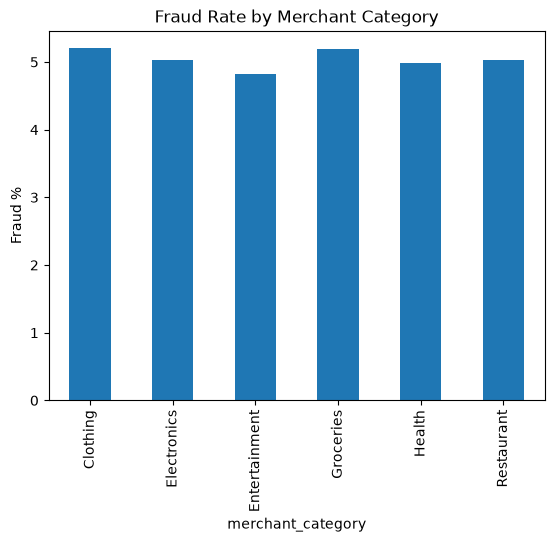

In [17]:
(df.groupby("merchant_category")["is_fraud"].mean() * 100).plot(kind="bar")  #category wise fraud
plt.title("Fraud Rate by Merchant Category")
plt.ylabel("Fraud %")
plt.show()

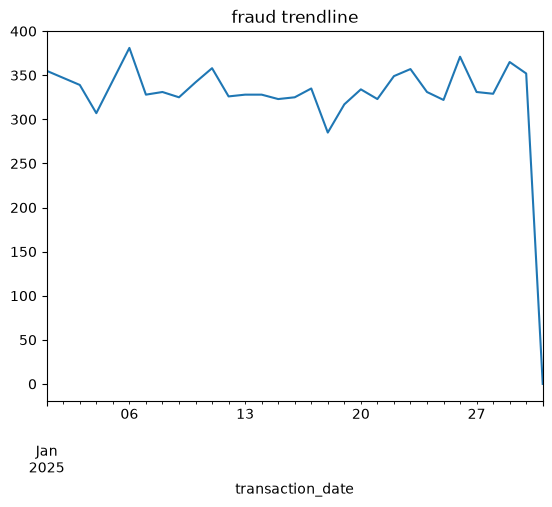

In [25]:
df.groupby("transaction_date")["is_fraud"].sum().plot() #fraud trendline
plt.title("fraud trendline")
plt.show()

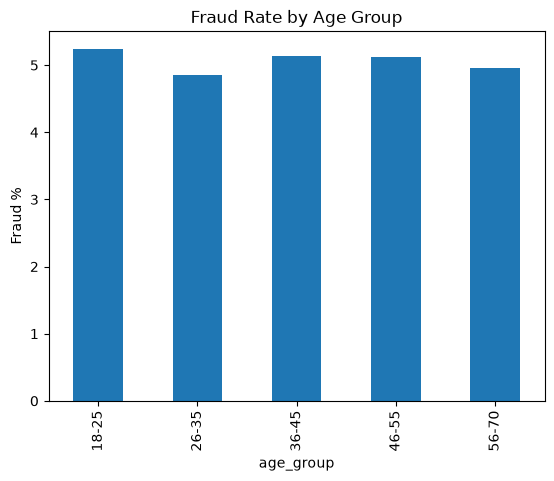

In [21]:
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 70], labels=["18-25", "26-35", "36-45", "46-55", "56-70"])

(df.groupby("age_group")["is_fraud"].mean() * 100).plot(kind="bar")
plt.title("Fraud Rate by Age Group")
plt.ylabel("Fraud %")
plt.show()

In [26]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

user = "root"
password = quote_plus("************")
host = "localhost"
database = "*****"

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}/{database}")

df.to_sql(
    name="transactions",
    con=engine,   # table pehle se ho to dobara banayega
    index=False,)

print("done")

done
